# Lululime — Dataverse 2026 Datathon

**Question:** Should Lululime expand loyalty perks and shut down the free repair program?
We judge this on **ARR** (revenue from repeat customers over the trailing 12 months) and **profit**:

> Profit = Revenue − Production cost − Repair cost − Redeemed points (20 pts = $1)

**Notebook outline**
1. Data cleaning & joining  ← *this section*
2. Behaviour (competitor impact, seasonality, tier-threshold behaviour)
3. Financials (loyalty revenue vs. profit, points & returns)
4. Segments (Silver demotion, Pilates campaign, repair users & churn)
5. Strategy (scenario modelling of ARR/profit, KPIs)

## 0. Setup

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Put customers.csv, sales.csv and items.csv in a data/ folder next to this notebook
DATA_DIR = Path("data")
OUT_DIR = Path("clean")
OUT_DIR.mkdir(exist_ok=True)

# Key dates from the case
LOYALTY_START   = pd.Timestamp("2024-06-01")
PILATES_START   = pd.Timestamp("2025-01-06")
PILATES_END     = pd.Timestamp("2025-03-31")
REPAIR_START    = pd.Timestamp("2025-04-01")
WEBSITE_LAUNCH  = pd.Timestamp("2025-11-17")
NEW_MANAGER     = pd.Timestamp("2026-02-02")
POINTS_PER_DOLLAR_REDEEMED = 20

## 1. Load raw data

In [10]:
customers_raw = pd.read_csv(DATA_DIR / "customers.csv")
items_raw     = pd.read_csv(DATA_DIR / "items.csv")
sales_raw     = pd.read_csv(DATA_DIR / "sales.csv",
                            dtype={"transaction_id": str, "item_id": str, "row_type": str,
                                   "original_transaction_id": str, "tier_at_purchase": str,
                                   "notes": str})

for name, df in [("customers", customers_raw), ("items", items_raw), ("sales", sales_raw)]:
    print(f"{name:10s} {df.shape}")

customers  (14440, 7)
items      (38, 7)
sales      (352014, 14)


In [11]:
# Missing values per column
pd.concat({"customers": customers_raw.isna().sum(), "sales": sales_raw.isna().sum()}, axis=1).fillna("")

,customers,sales
customer_id,0.0,0.0
signup_date,0.0,
age_band,276.0,
home_area,423.0,
acquisition_channel,0.0,
interests,0.0,
loyalty_join_date,7722.0,
transaction_id,,0.0
date,,0.0
time,,0.0


## 2. Data-quality audit

Before changing anything, we check each issue we found while exploring the data.
Every fix below is tied to one of these checks.

In [12]:
audit = {}

# 2a. Exact duplicate rows in sales (identical on every column, incl. transaction_id + time)
audit["exact duplicate sales rows"] = sales_raw.duplicated().sum()

# 2b. Keys: every sales row should map to a known customer and item
audit["sales rows w/ unknown customer"] = (~sales_raw.customer_id.isin(customers_raw.customer_id)).sum()
audit["sales rows w/ unknown item"]     = (~sales_raw.item_id.isin(items_raw.item_id)).sum()
audit["duplicate customer_ids"]         = customers_raw.customer_id.duplicated().sum()

# 2c. Loyalty fields are blank before the program launched
d = pd.to_datetime(sales_raw.date)
audit["tier blank BEFORE launch"] = sales_raw.loc[d <  LOYALTY_START, "tier_at_purchase"].isna().sum()
audit["tier blank AFTER launch"]  = sales_raw.loc[d >= LOYALTY_START, "tier_at_purchase"].isna().sum()
audit["points blank on Non-member rows"] = (
    sales_raw.loc[sales_raw.tier_at_purchase.eq("Non-member"), "points_earned"].isna().sum())

# 2d. Returns
ret = sales_raw[sales_raw.row_type == "Return"]
audit["returns without original_transaction_id"] = ret.original_transaction_id.isna().sum()

# 2e. Repairs
drop = sales_raw[sales_raw.row_type == "Repair Drop-off"]
pick = sales_raw[sales_raw.row_type == "Repair Pickup"]
audit["repair drop-offs never picked up"] = (~drop.transaction_id.isin(pick.original_transaction_id)).sum()

# 2f. Customer attributes
audit["customers missing age_band"]  = customers_raw.age_band.isna().sum()
audit["customers missing home_area"] = customers_raw.home_area.isna().sum()

pd.Series(audit, name="count").to_frame()

,count
exact duplicate sales rows,1016
sales rows w/ unknown customer,0
sales rows w/ unknown item,0
duplicate customer_ids,0
tier blank BEFORE launch,129963
tier blank AFTER launch,0
points blank on Non-member rows,24720
returns without original_transaction_id,141
repair drop-offs never picked up,259
customers missing age_band,276


In [13]:
# A look at the duplicates: they're same transaction, same item, same second -> double scans.
# Genuine multi-unit purchases are recorded with quantity >= 2, so these are safe to drop.
dups = sales_raw[sales_raw.duplicated(keep=False)]
print(dups.row_type.value_counts().to_string())
dups.head(6)

row_type
Purchase           1868
Return               96
Repair Drop-off      34
Repair Pickup        34


,transaction_id,date,time,customer_id,item_id,quantity,unit_price_paid,row_type,original_transaction_id,tier_at_purchase,points_earned,points_redeemed,points_balance_after,notes
596,T1000351,2022-11-04,11:26:07,913740,H01,1,128.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN
597,T1000351,2022-11-04,11:26:07,913740,H01,1,128.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN
708,T1000419,2022-11-04,17:04:09,220013,T01,1,78.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN
709,T1000419,2022-11-04,17:04:09,220013,T01,1,78.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN
882,T1000509,2022-11-05,13:27:25,164384,H03,1,148.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN
883,T1000509,2022-11-05,13:27:25,164384,H03,1,148.0,Purchase,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean `items`
- Flag repair "items" (R01/R02): their `production_cost` is the **cost to do the repair**, and their price is $0.
- Gross margin per item is useful later.

In [14]:
items = items_raw.copy()
items["is_repair"] = items.category.eq("Repairs")
items["list_margin"] = items.price - items.production_cost
items["margin_pct"] = np.where(items.price > 0, items.list_margin / items.price, np.nan)
items.head()

,item_id,item_name,category,activity,season,price,production_cost,is_repair,list_margin,margin_pct
0,L01,Flow High-Rise Legging,Leggings,Yoga,All-Season,98,36,False,62,0.632653
1,L02,Pace Tight 25in,Leggings,Run,All-Season,118,44,False,74,0.627119
2,L03,Studio Crop Legging,Leggings,Pilates,All-Season,88,33,False,55,0.625000
3,L04,Everyday Jogger,Leggings,Lifestyle,All-Season,108,41,False,67,0.620370
4,L05,Trail Hike Pant,Leggings,Outdoor,All-Season,128,50,False,78,0.609375


## 4. Clean `customers`
- Parse dates.
- Fill missing `age_band` / `home_area` with `"Unknown"` (≈2–3% of customers), so these customers stay in totals but show up as their own group.
- Turn `interests` (semicolon list) into one 0/1 column per activity.
- Add flags: loyalty member, Pilates-campaign acquisition, and whether they **signed up before the sales window** (Nov 2022). Their history before Nov 2022 isn't in the data, so their first visit we can see isn't their real first visit.

In [15]:
customers = customers_raw.copy()
customers["signup_date"]       = pd.to_datetime(customers.signup_date)
customers["loyalty_join_date"] = pd.to_datetime(customers.loyalty_join_date)

customers["age_band"]  = customers.age_band.fillna("Unknown")
customers["home_area"] = customers.home_area.fillna("Unknown")
age_order = ["18-24", "25-34", "35-44", "45-54", "55+", "Unknown"]
customers["age_band"] = pd.Categorical(customers.age_band, categories=age_order, ordered=True)

interest_dummies = (customers.interests.str.get_dummies(sep=";")
                    .add_prefix("int_"))
customers = pd.concat([customers, interest_dummies], axis=1)

customers["is_member"]         = customers.loyalty_join_date.notna()
customers["pilates_campaign"]  = customers.acquisition_channel.eq("Pilates Campaign")
customers["signup_year"]       = customers.signup_date.dt.year
SALES_START = pd.to_datetime(sales_raw.date).min()
customers["pre_window_signup"] = customers.signup_date < SALES_START

# Sanity checks
assert customers.customer_id.is_unique
assert (customers.loyalty_join_date.dropna() >= LOYALTY_START).all(), "joins before launch"
assert (customers.loyalty_join_date.isna() | (customers.loyalty_join_date >= customers.signup_date)).all(), "joined before signup"
print(interest_dummies.sum().sort_values(ascending=False).to_string())
customers.head()

int_Yoga         6857
int_Lifestyle    5944
int_Run          5800
int_Outdoor      3816
int_Pilates      1668


,customer_id,signup_date,age_band,home_area,acquisition_channel,interests,loyalty_join_date,int_Lifestyle,int_Outdoor,int_Pilates,int_Run,int_Yoga,is_member,pilates_campaign,signup_year,pre_window_signup
0,100053,2023-08-17,18-24,Burnaby,Walk-in,Yoga;Lifestyle,NaT,1,0,0,0,1,False,False,2023,False
1,100061,2021-06-25,25-34,Point Grey,Walk-in,Lifestyle;Yoga,NaT,1,0,0,0,1,False,False,2021,True
2,100073,2025-02-18,25-34,Fairview,Walk-in,Run;Outdoor,2025-09-07,0,1,0,1,0,True,False,2025,False
3,100081,2021-07-09,25-34,Kitsilano,Referral,Yoga;Lifestyle,2024-06-14,1,0,0,0,1,True,False,2021,True
4,100090,2025-12-11,25-34,Burnaby,Walk-in,Yoga;Outdoor,NaT,0,1,0,0,1,False,False,2025,False


## 5. Clean `sales` (row level)
1. Drop the exact duplicate rows.
2. Parse `date` + `time` into one `datetime` column.
3. Loyalty fields:
   - Before 2024-06-01 the program didn't exist, so `tier_at_purchase` becomes `"Pre-program"`.
   - Non-member rows have blank points, which we set to 0.
4. Standardize the free-text `notes` (lowercase, trim spaces), then sort them into categories:
   - return reasons
   - repair issues
   - gift
   - race / marathon
   - Pilates-ad mentions

In [16]:
sales = sales_raw.drop_duplicates().copy()
print(f"dropped {len(sales_raw) - len(sales):,} duplicate rows -> {len(sales):,} rows")

sales["date"] = pd.to_datetime(sales.date)
sales["datetime"] = pd.to_datetime(sales.date.dt.strftime("%Y-%m-%d") + " " + sales.time)

# Loyalty fields
sales["tier_at_purchase"] = sales.tier_at_purchase.fillna("Pre-program")
for col in ["points_earned", "points_redeemed"]:
    sales[col] = sales[col].fillna(0)
# points_balance_after stays NaN where it isn't defined (pre-program / non-member)
tier_order = ["Pre-program", "Non-member", "Member", "Silver", "Gold"]
sales["tier_at_purchase"] = pd.Categorical(sales.tier_at_purchase, categories=tier_order, ordered=True)

assert (sales.loc[sales.date < LOYALTY_START, "tier_at_purchase"] == "Pre-program").all()
assert (sales.loc[sales.date >= LOYALTY_START, "tier_at_purchase"] != "Pre-program").all()
sales.tier_at_purchase.value_counts().sort_index()

dropped 1,016 duplicate rows -> 350,998 rows


tier_at_purchase
Pre-program    129582
Non-member      24656
Member          47103
Silver          42421
Gold           107236
Name: count, dtype: int64

In [17]:
# Notes: normalize + categorize
sales["notes_clean"] = sales.notes.str.strip().str.lower()

RETURN_REASONS = {"changed mind", "size swap", "didnt fit", "wrong size", "defect"}
REPAIR_ISSUES  = {"broken zipper", "zipper", "hole in sleeve", "seam split", "torn seam", "delaminating"}
GIFT_WORDS     = {"gift", "xmas gift", "gift receipt please", "for my sister"}
RACE_WORDS     = {"need new shorts for race", "first marathon!", "race day kit", "bmo prep",
                  "training for the half", "marathon in may"}
PILATES_WORDS  = {"saw the pilates ad", "reformer class recommended", "new to pilates", "pilates ig post"}

def note_category(n):
    if pd.isna(n):            return np.nan
    if n in RETURN_REASONS:   return "return_reason"
    if n in REPAIR_ISSUES:    return "repair_issue"
    if n in GIFT_WORDS:       return "gift"
    if n in RACE_WORDS:       return "race"
    if n in PILATES_WORDS:    return "pilates_ad"
    return "other"

sales["note_category"] = sales.notes_clean.map(note_category)
# Merge spelling variants of the same reason
sales["notes_clean"] = sales.notes_clean.replace({"zipper": "broken zipper", "didnt fit": "wrong size"})
sales["is_gift"] = sales.note_category.eq("gift")

print(sales.note_category.value_counts(dropna=False).to_string())
pd.crosstab(sales.notes_clean, sales.row_type).loc[lambda t: t.sum(axis=1) > 0]

note_category
NaN              330449
return_reason     12452
repair_issue       4697
gift               2172
race               1175
pilates_ad           53


row_type,Purchase,Repair Drop-off,Return
notes_clean,,,
bmo prep,197,0,0
broken zipper,0,1551,0
changed mind,0,0,2533
defect,0,0,2418
delaminating,0,785,0
first marathon!,208,0,0
for my sister,303,0,0
gift,1225,0,0
gift receipt please,320,0,0


In [18]:
# Do note categories only show up on the row types we'd expect?
pd.crosstab(sales.note_category, sales.row_type)

row_type,Purchase,Repair Drop-off,Return
note_category,,,
gift,2172,0,0
pilates_ad,53,0,0
race,1175,0,0
repair_issue,0,4697,0
return_reason,0,0,12452


## 6. Join items, then compute line-level money

Rules (they follow the case's profit definition):

| row_type | revenue | production cost | repair cost |
|---|---|---|---|
| Purchase | qty × unit_price_paid | qty × production_cost | 0 |
| Return (qty = −1) | negative (refund) | negative: item goes back to stock (**assumption**) | 0 |
| Repair Drop-off | 0 | 0 | repair cost (charged at drop-off, even if never picked up) |
| Repair Pickup | 0 | 0 | 0 (already counted at drop-off) |

Redeemed points are counted **per transaction** in §7, because the case warns that `points_redeemed` is split across the rows of a transaction.

> **Assumption to state on the methodology slide:** returned items are restocked, so production cost is reversed.
> The switch below lets us treat `defect` returns as a write-off (cost not recovered), so we can test how sensitive the results are.

In [19]:
DEFECT_RETURNS_WRITTEN_OFF = False   # sensitivity toggle

sales = sales.merge(items[["item_id", "item_name", "category", "activity", "season",
                           "price", "production_cost", "is_repair"]],
                    on="item_id", how="left", validate="many_to_one")

is_purchase = sales.row_type.eq("Purchase")
is_return   = sales.row_type.eq("Return")
is_dropoff  = sales.row_type.eq("Repair Drop-off")

sales["revenue"]   = np.where(is_purchase | is_return, sales.quantity * sales.unit_price_paid, 0.0)
sales["prod_cost"] = np.where(is_purchase | is_return, sales.quantity * sales.production_cost, 0.0)
if DEFECT_RETURNS_WRITTEN_OFF:
    sales.loc[is_return & sales.notes_clean.eq("defect"), "prod_cost"] = 0.0
sales["repair_cost"] = np.where(is_dropoff, sales.production_cost, 0.0)

# Discounts: compare paid price to list price
sales["discount_pct"] = np.where(sales.price > 0, 1 - sales.unit_price_paid / sales.price, 0).round(2)
sales["promo"] = np.select([sales.discount_pct.eq(0.25), sales.discount_pct.eq(0.30)],
                           ["Black Friday", "Boxing Week"], default="Full price")

assert sales.item_name.notna().all()
assert set(sales.discount_pct.unique()) <= {0.0, 0.25, 0.30}
# Discounted purchases should only fall on Black Friday weekend / Boxing Week
dp = sales[is_purchase & sales.promo.ne("Full price")]
print(dp.groupby("promo").date.apply(lambda d: sorted(d.dt.strftime("%m-%d").unique())).to_string())
print(sales[is_purchase].promo.value_counts().to_string())

promo
Black Friday    [11-24, 11-25, 11-26, 11-27, 11-28, 11-29, 11-...
Boxing Week            [12-26, 12-27, 12-28, 12-29, 12-30, 12-31]
promo
Full price      303045
Boxing Week      13058
Black Friday      6666


## 7. Link returns to their original purchases
Each return points back to its original purchase through `original_transaction_id`.
The 141 returns with no link are all from Nov–Dec 2022. Their original purchase was before the data starts, so we keep them and mark them `orphan_return`.

In [20]:
purch_lines = (sales.loc[is_purchase, ["transaction_id", "item_id", "date", "customer_id"]]
                    .drop_duplicates(["transaction_id", "item_id"])
                    .rename(columns={"transaction_id": "original_transaction_id",
                                     "date": "orig_date", "customer_id": "orig_customer"}))
sales = sales.merge(purch_lines, on=["original_transaction_id", "item_id"], how="left")

ret_mask = sales.row_type.eq("Return")
sales["orphan_return"] = ret_mask & sales.orig_date.isna()
sales.loc[ret_mask, "days_to_return"] = (sales.date - sales.orig_date).dt.days

linked = sales[ret_mask & ~sales.orphan_return]
assert (linked.customer_id == linked.orig_customer).all(), "return customer != buyer"
print("orphan returns:", sales.orphan_return.sum(), "| all in", sales.loc[sales.orphan_return, "date"].dt.year.unique())
sales.loc[ret_mask, "days_to_return"].describe()

orphan returns: 141 | all in [2022]


count    17387.000000
mean        13.941105
std          6.651813
min          3.000000
25%          8.000000
50%         14.000000
75%         20.000000
max         26.000000
Name: days_to_return, dtype: float64

## 8. Build the repair table (drop-off → pickup)
One row per repair, with:
- turnaround in days
- whether it was picked up
- whether it's still **open**

If a drop-off happened recently, the item may simply not be ready yet. So a missing pickup only counts as **abandoned** once more than 45 days have passed by the end of the data (the longest turnaround we see is 47 days).

In [21]:
drop = sales[sales.row_type.eq("Repair Drop-off")]
pick = sales[sales.row_type.eq("Repair Pickup")]
assert pick.original_transaction_id.isin(drop.transaction_id).all()

repairs = (drop[["transaction_id", "customer_id", "date", "item_id", "item_name", "notes_clean",
                 "tier_at_purchase", "repair_cost"]]
           .rename(columns={"transaction_id": "dropoff_id", "date": "dropoff_date",
                            "notes_clean": "issue", "tier_at_purchase": "tier_at_dropoff"})
           .merge(pick[["original_transaction_id", "item_id", "transaction_id", "date"]]
                  .rename(columns={"original_transaction_id": "dropoff_id",
                                   "transaction_id": "pickup_id", "date": "pickup_date"}),
                  on=["dropoff_id", "item_id"], how="left", validate="one_to_one"))
# A repair = one item in one drop-off (68 drop-offs hold 2 items; pickups can be split across visits)

DATA_END = sales.date.max()
repairs["turnaround_days"] = (repairs.pickup_date - repairs.dropoff_date).dt.days
repairs["picked_up"] = repairs.pickup_date.notna()
repairs["status"] = np.select(
    [repairs.picked_up, (DATA_END - repairs.dropoff_date).dt.days <= 45],
    ["picked up", "open"], default="abandoned")

print(repairs.status.value_counts().to_string())
print("unpicked drop-offs are all from:", repairs.loc[~repairs.picked_up, "dropoff_date"].min().date(), "onward")
repairs.turnaround_days.describe()

status
picked up    5221
open          259
unpicked drop-offs are all from: 2026-10-01 onward


count    5221.000000
mean       15.230033
std         9.086122
min         5.000000
25%         9.000000
50%        13.000000
75%        17.000000
max        47.000000
Name: turnaround_days, dtype: float64

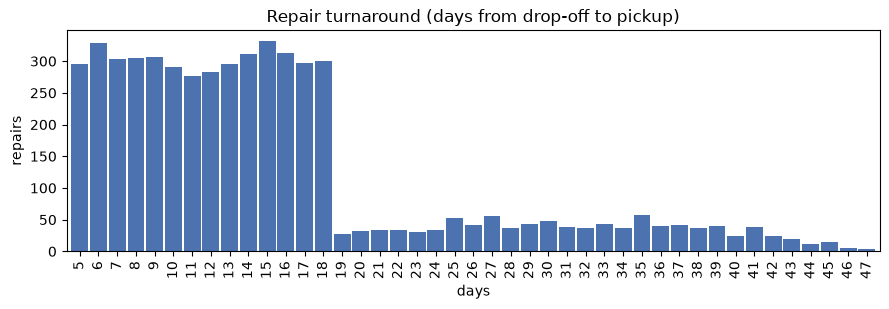

,share slow (>18d)
dropoff_date,
2025Q2,0.000
2025Q3,0.000
2025Q4,0.470
2026Q1,0.316
2026Q2,0.000
2026Q3,0.000
2026Q4,0.038


In [22]:
# Turnaround has two humps: most repairs come back in 5–18 days, then a long slow tail.
# We'll use that split later to check whether slow turnaround hurts retention.
fig, ax = plt.subplots(figsize=(9, 3.2))
repairs.turnaround_days.dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax, width=0.9, color="#4C72B0")
ax.set(title="Repair turnaround (days from drop-off to pickup)", xlabel="days", ylabel="repairs")
plt.tight_layout(); plt.show()

repairs["slow_repair"] = repairs.turnaround_days > 18
repairs.groupby(repairs.dropoff_date.dt.to_period("Q")).slow_repair.mean().round(3).to_frame("share slow (>18d)")

## 9. Transaction-level table
Roll the rows up to one row per visit (`transaction_id`).
- `points_redeemed` is **summed** within the transaction.
- `points_balance_after` is the same on every row, so we take it **once** (`first`).
- `points_cost = points_redeemed / 20` is the dollar value of the discount, which comes out of profit.

In [23]:
txn = (sales.groupby("transaction_id", sort=False)
            .agg(customer_id=("customer_id", "first"),
                 datetime=("datetime", "first"),
                 date=("date", "first"),
                 has_purchase=("row_type", lambda r: (r == "Purchase").any()),
                 has_return=("row_type", lambda r: (r == "Return").any()),
                 has_dropoff=("row_type", lambda r: (r == "Repair Drop-off").any()),
                 has_pickup=("row_type", lambda r: (r == "Repair Pickup").any()),
                 visit_type=("row_type", lambda r: " + ".join(sorted(set(r)))),
                 tier=("tier_at_purchase", "first"),
                 n_lines=("item_id", "size"),
                 units=("quantity", "sum"),
                 revenue=("revenue", "sum"),
                 prod_cost=("prod_cost", "sum"),
                 repair_cost=("repair_cost", "sum"),
                 points_earned=("points_earned", "sum"),
                 points_redeemed=("points_redeemed", "sum"),
                 points_balance_after=("points_balance_after", "first"),
                 promo=("promo", "first"),
                 has_outerwear=("category", lambda c: (c == "Outerwear").any()),
                 is_gift=("is_gift", "any"))
            .reset_index())

# One tier / balance per transaction?
chk = sales.groupby("transaction_id").agg(tr=("tier_at_purchase", "nunique"),
                                          bal=("points_balance_after", "nunique"))
assert (chk.tr == 1).all() and (chk.bal <= 1).all()

# A visit can mix row types: many repair drop-offs/pickups happen in the same visit as a purchase.
# This matters for the repair story (repair visits bring people into the store).
print(txn.visit_type.value_counts().to_string())

txn["points_cost"] = txn.points_redeemed / POINTS_PER_DOLLAR_REDEEMED
txn["profit"] = txn.revenue - txn.prod_cost - txn.repair_cost - txn.points_cost
txn["points_share_of_spend"] = np.where(txn.revenue > 0, txn.points_cost / txn.revenue, 0)

# Points rules from the case: redemptions in blocks of 100; earn rate matches tier
assert (txn.points_redeemed % 100 == 0).all()
p = txn[txn.has_purchase & ~txn.has_return & (txn.revenue > 0)]
print((p.points_earned / p.revenue).groupby(p.tier, observed=True).median().round(3).to_string())
txn.head()

visit_type
Purchase                      161995
Return                         17528
Purchase + Repair Drop-off      4128
Repair Pickup                   2861
Purchase + Repair Pickup        2360
Repair Drop-off                 1284
tier
Pre-program    0.000
Non-member     0.000
Member         1.000
Silver         1.249
Gold           1.500


,transaction_id,customer_id,datetime,date,has_purchase,has_return,has_dropoff,has_pickup,visit_type,tier,n_lines,units,revenue,prod_cost,repair_cost,points_earned,points_redeemed,points_balance_after,promo,has_outerwear,is_gift,points_cost,profit,points_share_of_spend
0,T1000001,180984,2022-11-01 10:27:32,2022-11-01,True,False,False,False,Purchase,Pre-program,2,2,156.0,54.0,0.0,0.0,0.0,NaN,Full price,False,False,0.0,102.0,0.0
1,T1000002,939082,2022-11-01 10:27:55,2022-11-01,True,False,False,False,Purchase,Pre-program,1,1,38.0,11.0,0.0,0.0,0.0,NaN,Full price,False,False,0.0,27.0,0.0
2,T1000003,884202,2022-11-01 10:52:43,2022-11-01,True,False,False,False,Purchase,Pre-program,5,5,514.0,190.0,0.0,0.0,0.0,NaN,Full price,False,False,0.0,324.0,0.0
3,T1000004,110076,2022-11-01 11:03:09,2022-11-01,True,False,False,False,Purchase,Pre-program,2,2,312.0,121.0,0.0,0.0,0.0,NaN,Full price,True,False,0.0,191.0,0.0
4,T1000005,554756,2022-11-01 11:03:35,2022-11-01,True,False,False,False,Purchase,Pre-program,1,1,108.0,42.0,0.0,0.0,0.0,NaN,Full price,False,False,0.0,66.0,0.0


## 10. Customer-level enrichment
Add lifetime stats and repair usage for each customer. ARR / churn come in later sections.

In [24]:
purch_txn = txn[txn.has_purchase]
cust_stats = (purch_txn.groupby("customer_id")
              .agg(first_purchase=("date", "min"), last_purchase=("date", "max"),
                   n_visits=("transaction_id", "nunique"), gross_revenue=("revenue", "sum")))
cust_net = txn.groupby("customer_id")[["revenue", "prod_cost", "repair_cost", "points_cost", "profit"]].sum() \
              .add_prefix("net_")
cust_rep = repairs.groupby("customer_id").agg(n_repairs=("dropoff_id", "size"),
                                              first_repair=("dropoff_date", "min"))
cust_ret = sales[sales.row_type == "Return"].groupby("customer_id").size().rename("n_returns")

customers = (customers.set_index("customer_id")
             .join([cust_stats, cust_net, cust_rep, cust_ret])
             .fillna({"n_visits": 0, "n_repairs": 0, "n_returns": 0})
             .reset_index())
customers["repair_user"] = customers.n_repairs > 0
customers["repeat_customer"] = customers.n_visits >= 2

print(f"customers: {len(customers):,} | repair users: {customers.repair_user.sum():,} "
      f"| members: {customers.is_member.sum():,} | repeat: {customers.repeat_customer.sum():,}")
customers.describe(include="all").T.head(30)

customers: 14,440 | repair users: 2,175 | members: 6,718 | repeat: 11,702


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,14440.0,NaN,NaN,NaN,551108.133033,100053.0,328334.25,552270.5,776187.75,999973.0,260232.352636
signup_date,14440,NaN,NaN,NaN,2023-07-17 19:03:49.362881,2018-03-01 00:00:00,2022-02-16 00:00:00,2023-10-13 00:00:00,2025-03-11 00:00:00,2026-10-31 00:00:00,NaN
age_band,14440,6,25-34,5279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_area,14440,9,Kitsilano,3356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_channel,14440,4,Walk-in,7625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
interests,14440,25,Yoga,1472,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loyalty_join_date,6718,NaN,NaN,NaN,2025-04-14 11:03:11.842810,2024-06-01 00:00:00,2024-08-18 00:00:00,2025-02-02 00:00:00,2025-11-06 00:00:00,2026-10-31 00:00:00,NaN
int_Lifestyle,14440.0,NaN,NaN,NaN,0.411634,0.0,0.0,0.0,1.0,1.0,0.492147
int_Outdoor,14440.0,NaN,NaN,NaN,0.264266,0.0,0.0,0.0,1.0,1.0,0.440957
int_Pilates,14440.0,NaN,NaN,NaN,0.115512,0.0,0.0,0.0,0.0,1.0,0.31965


## 11. Final reconciliation & save

In [25]:
# Totals must match between row level and transaction level
for col in ["revenue", "prod_cost", "repair_cost"]:
    assert np.isclose(sales[col].sum(), txn[col].sum())
assert np.isclose(txn.points_redeemed.sum(), sales.points_redeemed.sum())

summary = pd.Series({
    "Gross revenue (purchases)":   sales.loc[sales.row_type == "Purchase", "revenue"].sum(),
    "Refunds (returns)":           sales.loc[sales.row_type == "Return", "revenue"].sum(),
    "Net revenue":                 txn.revenue.sum(),
    "Production cost (net)":       txn.prod_cost.sum(),
    "Repair cost":                 txn.repair_cost.sum(),
    "Redeemed points ($)":         txn.points_cost.sum(),
    "Profit":                      txn.profit.sum(),
}).map("${:,.0f}".format)
print(summary.to_string())

sales.to_csv(OUT_DIR / "sales_clean.csv", index=False)
txn.to_csv(OUT_DIR / "transactions.csv", index=False)
customers.to_csv(OUT_DIR / "customers_clean.csv", index=False)
repairs.to_csv(OUT_DIR / "repairs.csv", index=False)
items.to_csv(OUT_DIR / "items_clean.csv", index=False)
print("saved ->", OUT_DIR)

Gross revenue (purchases)    $27,628,041
Refunds (returns)            $-1,423,427
Net revenue                  $26,204,614
Production cost (net)         $9,701,687
Repair cost                     $187,983
Redeemed points ($)             $796,635
Profit                       $15,518,309
saved -> clean


### Cleaning log (for the methodology slide)
| Issue | Size | Fix |
|---|---|---|
| Exact duplicate sales rows (double-scans) | 1,016 rows | Dropped |
| Loyalty fields blank before 2024-06-01 | ~130k rows | Tier = "Pre-program"; points = 0 |
| Non-member rows have blank points | ~24.7k rows | Points = 0 |
| Returns with no link to an original purchase | 141 (all Nov–Dec 2022) | Kept, flagged `orphan_return` |
| Repair drop-offs not picked up | 259 | All dropped off in the final weeks, so still **open**, not abandoned. Repair cost still counted |
| Multi-item drop-offs | 68 drop-offs | A repair = one item in one drop-off |
| Visits that mix row types | 6,488 visits | Purchases made during a repair visit are kept; the visit gets flags (`has_purchase`, `has_dropoff`, ...) |
| Missing `age_band` / `home_area` | 276 / 423 customers | Labelled "Unknown" |
| Free-text notes in several spellings | ~20k rows | Lowercased, merged variants, sorted into 5 categories |
| `points_redeemed` split across a transaction's rows | — | Summed per transaction |
| `points_balance_after` repeated on every row | — | Taken once per transaction |
| Customers who signed up before Nov 2022 | 4,829 | Flagged `pre_window_signup` (their earlier history isn't in the data) |
| Return cost treatment | — | Assumed restocked; switch available for defect write-offs |